# RCEMIP-II 3D budget checks.

`thl_tend(t1)` is the mean over the output interval `[t0, t1]`. The advec/diff fluxes and `thl_tend_lw/sw/micro` are instantaneous.

Two checks, using dumped fields only:
- **Discrete:** `thl_tend(t1)` vs the change in `thl` over `[t0, t1]`.
- **Closure:** `thl_tend(t1)` vs the sum of adv+diff (divergence of the dumped fluxes), radiation (lw+sw) and micro.

In [1]:
%matplotlib ipympl

import matplotlib.pyplot as plt
import numpy as np

## Output every 1 s, full grid

Restart at `t0=172800` with output every second. 

- **Discrete:** `thl_tend(t1)` vs `thl(t1) - thl(t0)`, both over `[t0, t1]`.
- **Closure:** `thl_tend(t1)` vs the sum of advection + diffusion + radiation + micro at `t1`.


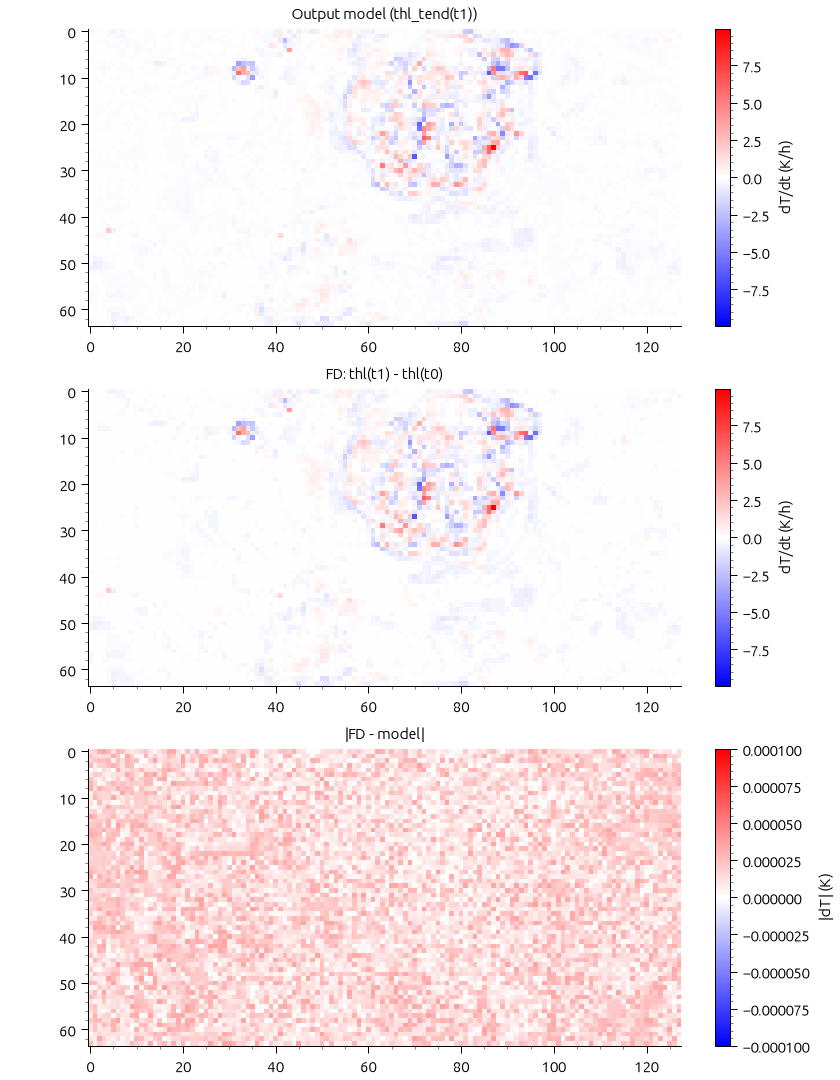

In [2]:
path = '/home/bart/meteo/projects_maq/2026_connecting_the_clouds/rcemip_ii_case_production/experiments/dev'

itot = 128
jtot = 64
ktot = 128

float_type = np.float32

t0 = 172800
t1 = t0+1

var = 'thl'

thl0 = np.fromfile(f'{path}/{var}.{t0:07d}', dtype=float_type).reshape((ktot, jtot, itot))
thl1 = np.fromfile(f'{path}/{var}.{t1:07d}', dtype=float_type).reshape((ktot, jtot, itot))

thlt_model = np.fromfile(f'{path}/{var}_tend.{t1:07d}', dtype=float_type).reshape((ktot, jtot, itot))
thlt_offli = (thl1 - thl0)

k = 3

vmax = np.abs(thlt_model[k]).max() * 3600
vmin = -vmax

plt.figure(figsize=(7,9), layout='constrained')
plt.subplot(311)
plt.title('Output model (thl_tend(t1))')
plt.imshow(thlt_model[k]*3600, vmin=vmin, vmax=vmax, cmap=plt.cm.bwr)
plt.colorbar(label='dT/dt (K/h)')

plt.subplot(312)
plt.title('FD: thl(t1) - thl(t0)')
plt.imshow(thlt_offli[k]*3600, vmin=vmin, vmax=vmax, cmap=plt.cm.bwr)
plt.colorbar(label='dT/dt (K/h)')

plt.subplot(313)
plt.title('|FD - model|')
plt.imshow(np.abs(thlt_offli[k]-thlt_model[k]), vmin=-0.0001, vmax=0.0001, cmap=plt.cm.bwr)
plt.colorbar(label='|dT| (K)')

In [3]:
xsize = 51200
ysize = 25600
zsize = 32343.68603421053

dx = xsize / itot
dy = ysize / jtot

def load(name, time):
    return np.fromfile(f'{path}/{name}.{time:07d}', dtype=float_type).reshape((ktot, jtot, itot))

grid = np.fromfile(f'{path}/grid.0000000', dtype=float_type)
z  = grid[2*itot+2*jtot : 2*itot+2*jtot+ktot]
zh = np.append(grid[2*itot+2*jtot+ktot :], zsize)
dz = zh[1:] - zh[:-1]

rho = np.fromfile(f'{path}/rhoref.0000000', dtype=float_type)
rhoref  = rho[:ktot]
rhorefh = rho[ktot:]

uthl = load('uthl', t1)
vthl = load('vthl', t1)
wthl = np.concatenate([load('wthl', t1), np.zeros((1, jtot, itot))], axis=0)

tend_advdiff = (
    - (np.roll(uthl, -1, axis=2) - uthl) / dx
    - (np.roll(vthl, -1, axis=1) - vthl) / dy
    - (rhorefh[1:,None,None] * wthl[1:] - rhorefh[:-1,None,None] * wthl[:-1]) / (rhoref[:,None,None] * dz[:,None,None]) )

tend_rad = load('thl_tend_lw', t1) + load('thl_tend_sw', t1)
tend_micro = load('thl_tend_micro', t1)

tend_recon = tend_advdiff + tend_rad + tend_micro

Text(0, 0.5, 'z (km)')

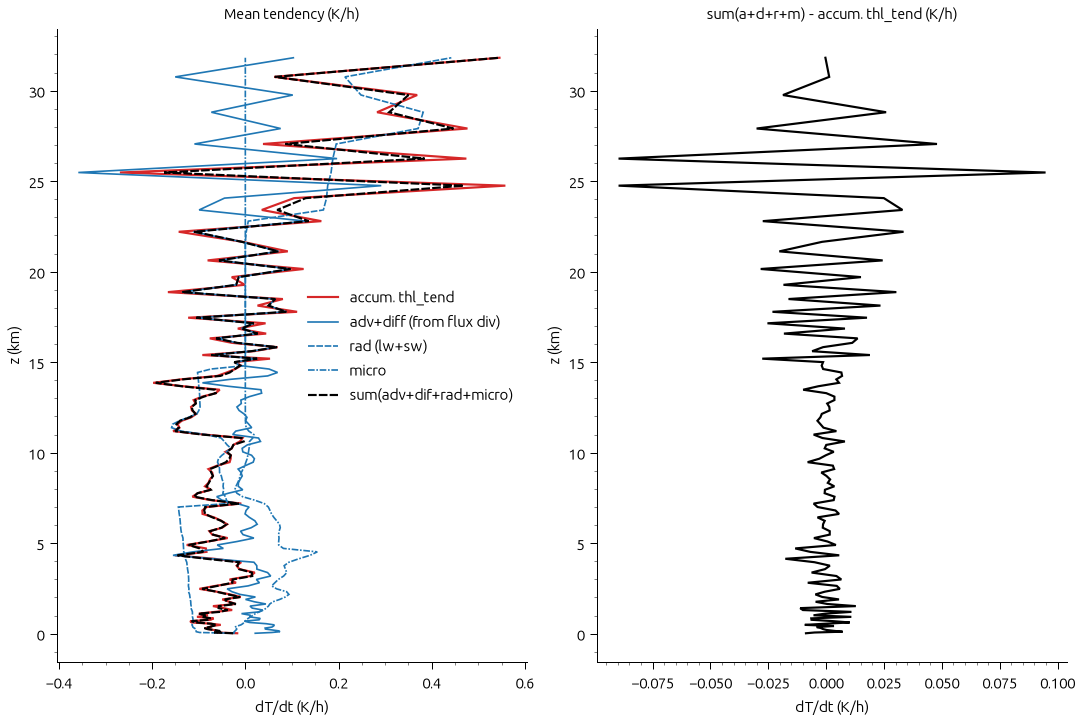

In [4]:
def hmean(a):
    return a.mean(axis=(1,2))

plt.figure(figsize=(9,6), layout='constrained')
plt.subplot(121)
plt.title('Mean tendency (K/h)')
plt.plot(hmean(thlt_model)*3600, z/1000, '-', color='tab:red', label='accum. thl_tend')
plt.plot(hmean(tend_advdiff)*3600, z/1000, '-', color='tab:blue', lw=1, label='adv+diff (from flux div)')
plt.plot(hmean(tend_rad)*3600, z/1000, '--', color='tab:blue', lw=1, label='rad (lw+sw)')
plt.plot(hmean(tend_micro)*3600, z/1000, '-.', color='tab:blue', lw=1, label='micro')
plt.plot(hmean(tend_recon)*3600, z/1000, '--', color='k', label='sum(adv+dif+rad+micro)')
plt.xlabel('dT/dt (K/h)')
plt.ylabel('z (km)')
plt.legend()

plt.subplot(122)
plt.title('sum(a+d+r+m) - accum. thl_tend (K/h)')
plt.plot(hmean(tend_recon - thlt_model)*3600, z/1000, '-', color='k')
plt.xlabel('dT/dt (K/h)')
plt.ylabel('z (km)')

## Moisture

**qt:** `qt_tend(t1)` vs adv+diff at `t1`. The qt micro and limiter tendencies aren't dumped, so this won't close where those act.

Text(0, 0.5, 'z (km)')

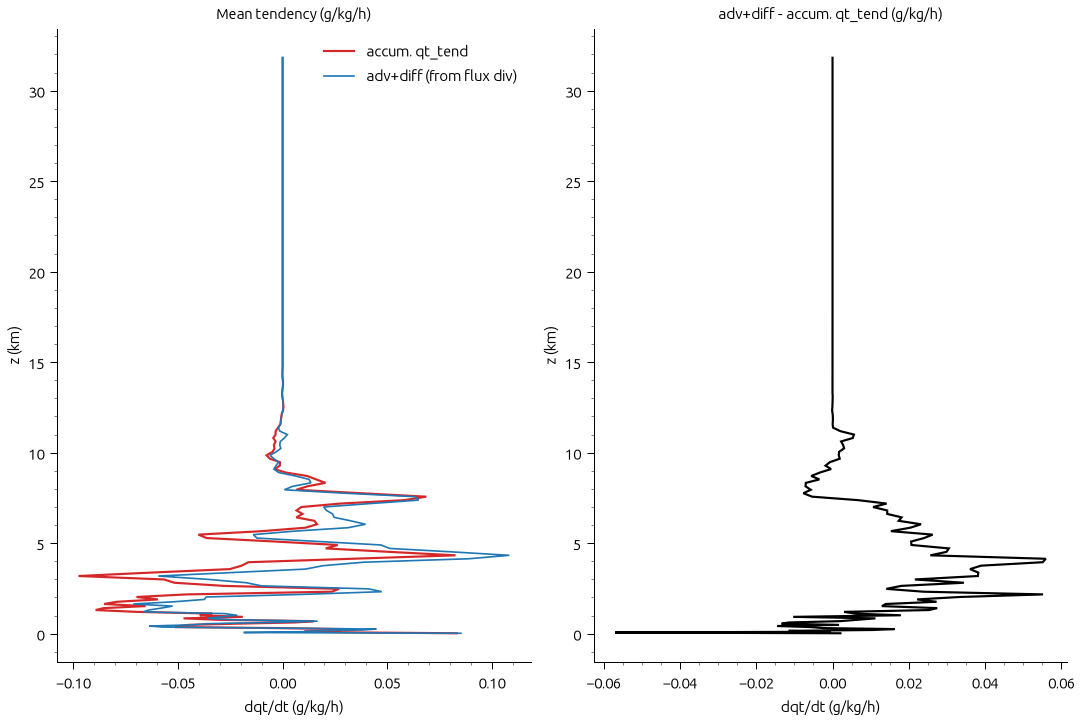

In [5]:
qt_tend = load('qt_tend', t1)

uqt = load('uqt', t1)
vqt = load('vqt', t1)
wqt = np.concatenate([load('wqt', t1), np.zeros((1, jtot, itot))], axis=0)

qt_advdiff = (
    - (np.roll(uqt, -1, axis=2) - uqt) / dx
    - (np.roll(vqt, -1, axis=1) - vqt) / dy
    - (rhorefh[1:,None,None] * wqt[1:] - rhorefh[:-1,None,None] * wqt[:-1]) / (rhoref[:,None,None] * dz[:,None,None]) )

plt.figure(figsize=(9,6), layout='constrained')
plt.subplot(121)
plt.title('Mean tendency (g/kg/h)')
plt.plot(hmean(qt_tend)*3600e3, z/1000, '-', color='tab:red', label='accum. qt_tend')
plt.plot(hmean(qt_advdiff)*3600e3, z/1000, '-', color='tab:blue', lw=1, label='adv+diff (from flux div)')
plt.xlabel('dqt/dt (g/kg/h)')
plt.ylabel('z (km)')
plt.legend()

plt.subplot(122)
plt.title('adv+diff - accum. qt_tend (g/kg/h)')
plt.plot(hmean(qt_advdiff - qt_tend)*3600e3, z/1000, '-', color='k')
plt.xlabel('dqt/dt (g/kg/h)')
plt.ylabel('z (km)')

## Output every 1 s, coarse grid

The same discrete and closure checks on the 8 x 8 coarsened `_c` fields, with the flux divergence computed using the coarse `dx` and `dy`.

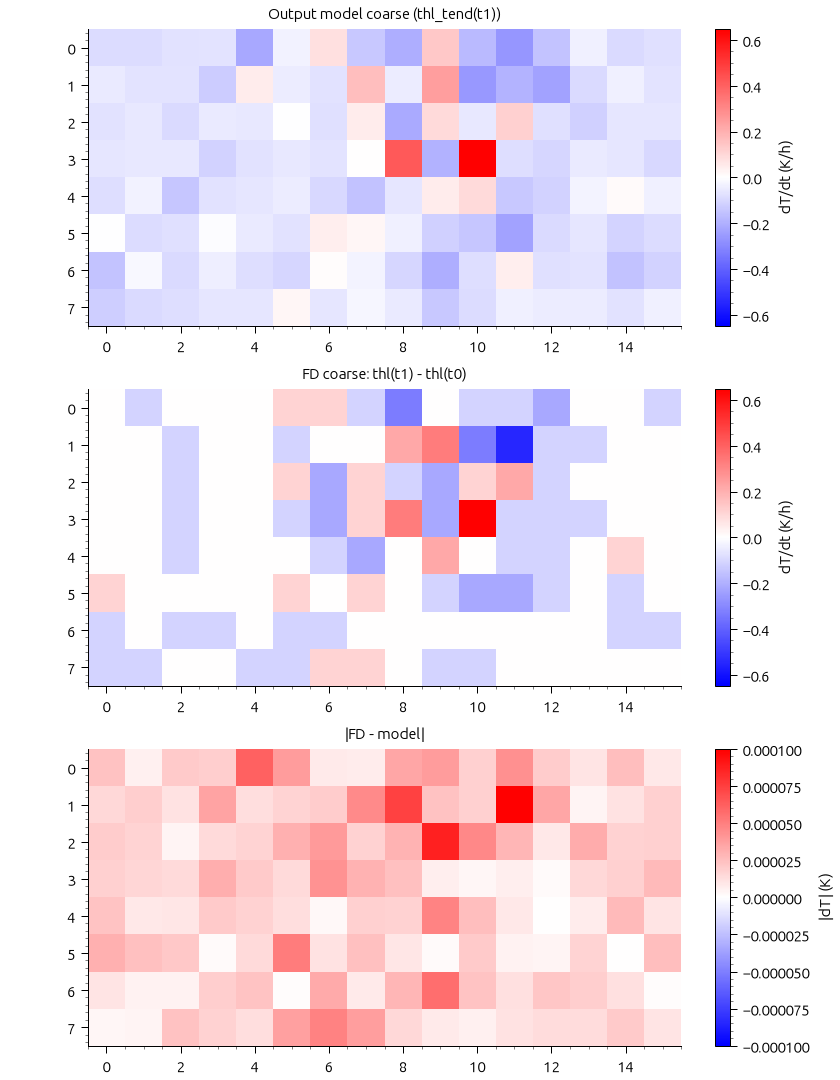

In [6]:
ratio_x = 8
ratio_y = 8

itot_c = itot // ratio_x
jtot_c = jtot // ratio_y

t0 = 172800
t1 = t0+1

def load_c(name, time):
    return np.fromfile(f'{path}/{name}_c.{time:07d}', dtype=float_type).reshape((ktot, jtot_c, itot_c))

thl0_c = load_c('thl', t0)
thl1_c = load_c('thl', t1)

thlt_model_c = load_c('thl_tend', t1)
thlt_offli_c = thl1_c - thl0_c

vmax = np.abs(thlt_model_c[k]).max() * 3600
vmin = -vmax

plt.figure(figsize=(7,9), layout='constrained')
plt.subplot(311)
plt.title('Output model coarse (thl_tend(t1))')
plt.imshow(thlt_model_c[k]*3600, vmin=vmin, vmax=vmax, cmap=plt.cm.bwr)
plt.colorbar(label='dT/dt (K/h)')

plt.subplot(312)
plt.title('FD coarse: thl(t1) - thl(t0)')
plt.imshow(thlt_offli_c[k]*3600, vmin=vmin, vmax=vmax, cmap=plt.cm.bwr)
plt.colorbar(label='dT/dt (K/h)')

plt.subplot(313)
plt.title('|FD - model|')
plt.imshow(np.abs(thlt_offli_c[k]-thlt_model_c[k]), vmin=-0.0001, vmax=0.0001, cmap=plt.cm.bwr)
plt.colorbar(label='|dT| (K)')

In [7]:
dx_c = xsize / itot_c
dy_c = ysize / jtot_c

uthl_c = load_c('uthl', t1)
vthl_c = load_c('vthl', t1)
wthl_c = np.concatenate([load_c('wthl', t1), np.zeros((1, jtot_c, itot_c))], axis=0)

tend_advdiff_c = (
    - (np.roll(uthl_c, -1, axis=2) - uthl_c) / dx_c
    - (np.roll(vthl_c, -1, axis=1) - vthl_c) / dy_c
    - (rhorefh[1:,None,None] * wthl_c[1:] - rhorefh[:-1,None,None] * wthl_c[:-1]) / (rhoref[:,None,None] * dz[:,None,None]) )

tend_rad_c = load_c('thl_tend_lw', t1) + load_c('thl_tend_sw', t1)
tend_micro_c = load_c('thl_tend_micro', t1)

tend_recon_c = tend_advdiff_c + tend_rad_c + tend_micro_c

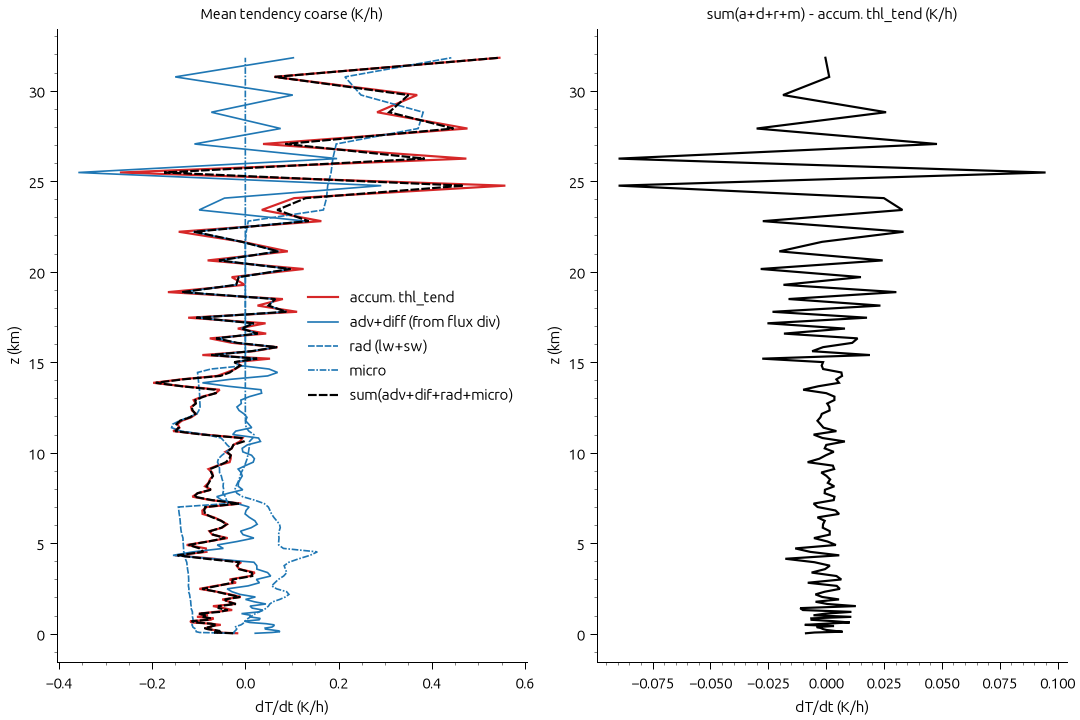

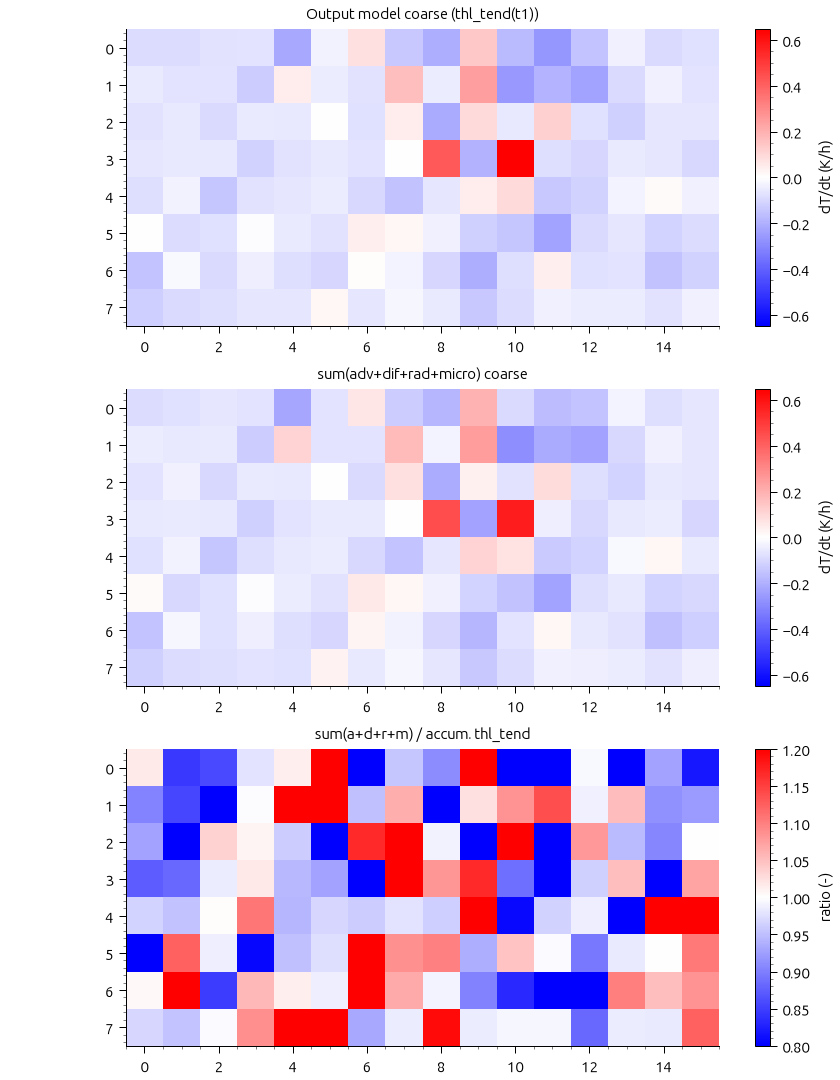

In [8]:
plt.figure(figsize=(9,6), layout='constrained')
plt.subplot(121)
plt.title('Mean tendency coarse (K/h)')
plt.plot(hmean(thlt_model_c)*3600, z/1000, '-', color='tab:red', label='accum. thl_tend')
plt.plot(hmean(tend_advdiff_c)*3600, z/1000, '-', color='tab:blue', lw=1, label='adv+diff (from flux div)')
plt.plot(hmean(tend_rad_c)*3600, z/1000, '--', color='tab:blue', lw=1, label='rad (lw+sw)')
plt.plot(hmean(tend_micro_c)*3600, z/1000, '-.', color='tab:blue', lw=1, label='micro')
plt.plot(hmean(tend_recon_c)*3600, z/1000, '--', color='k', label='sum(adv+dif+rad+micro)')
plt.xlabel('dT/dt (K/h)')
plt.ylabel('z (km)')
plt.legend()

plt.subplot(122)
plt.title('sum(a+d+r+m) - accum. thl_tend (K/h)')
plt.plot(hmean(tend_recon_c - thlt_model_c)*3600, z/1000, '-', color='k')
plt.xlabel('dT/dt (K/h)')
plt.ylabel('z (km)')

vmax = np.abs(thlt_model_c[k]).max() * 3600
vmin = -vmax

plt.figure(figsize=(7,9), layout='constrained')
plt.subplot(311)
plt.title('Output model coarse (thl_tend(t1))')
plt.imshow(thlt_model_c[k]*3600, vmin=vmin, vmax=vmax, cmap=plt.cm.bwr)
plt.colorbar(label='dT/dt (K/h)')

plt.subplot(312)
plt.title('sum(adv+dif+rad+micro) coarse')
plt.imshow(tend_recon_c[k]*3600, vmin=vmin, vmax=vmax, cmap=plt.cm.bwr)
plt.colorbar(label='dT/dt (K/h)')

plt.subplot(313)
plt.title('sum(a+d+r+m) / accum. thl_tend')
plt.imshow(tend_recon_c[k]/thlt_model_c[k], vmin=0.8, vmax=1.2, cmap=plt.cm.bwr)
plt.colorbar(label='ratio (-)')

## Output every 1 h, coarse grid

Hourly output only exists on the coarse grid. Here `t1 = t0 + 1 h` and `thl_tend(t1)` is the mean over `[t0, t1]`, so a single snapshot is not comparable to it.

- **Discrete:** `thl_tend(t1)` vs `thl(t1) - thl(t0)`. These are identical!
- **Closure:** `thl_tend(t1)` vs the sum, with each term averaged over the snapshots at `t0` and `t1`.

The sum agrees +/- with  `thl_tend(t1)` but is much noisier, because it averages only the two snapshots at `t0` and `t1` instead of every RK substep.

max |FD - model| (K/h): 0.0022535475


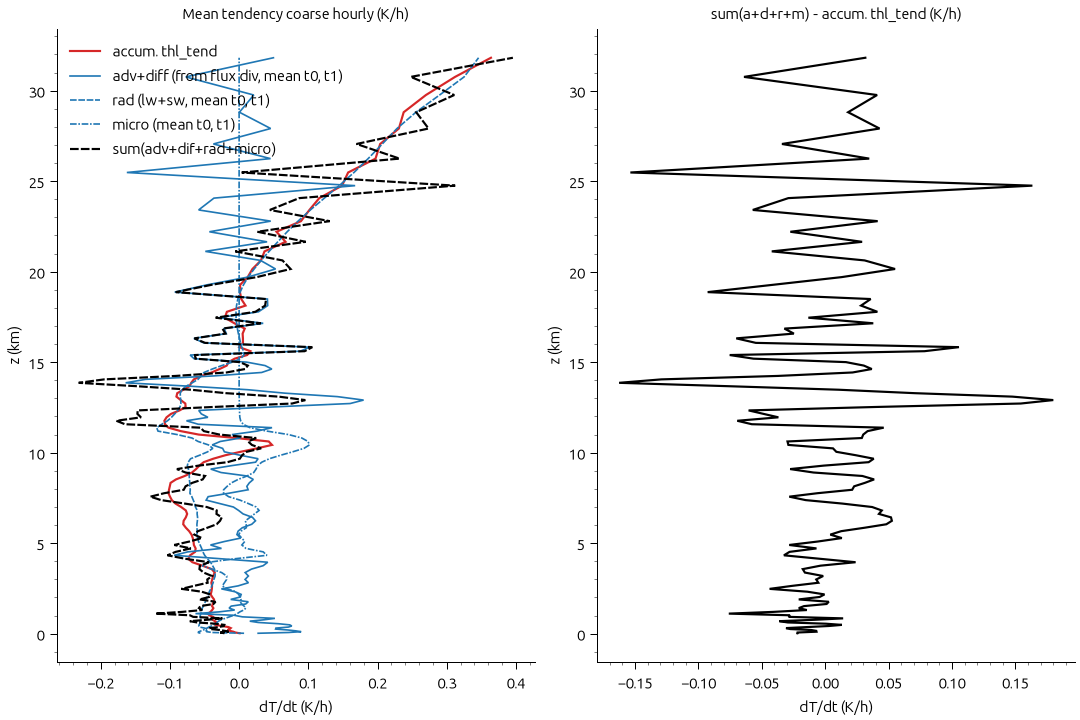

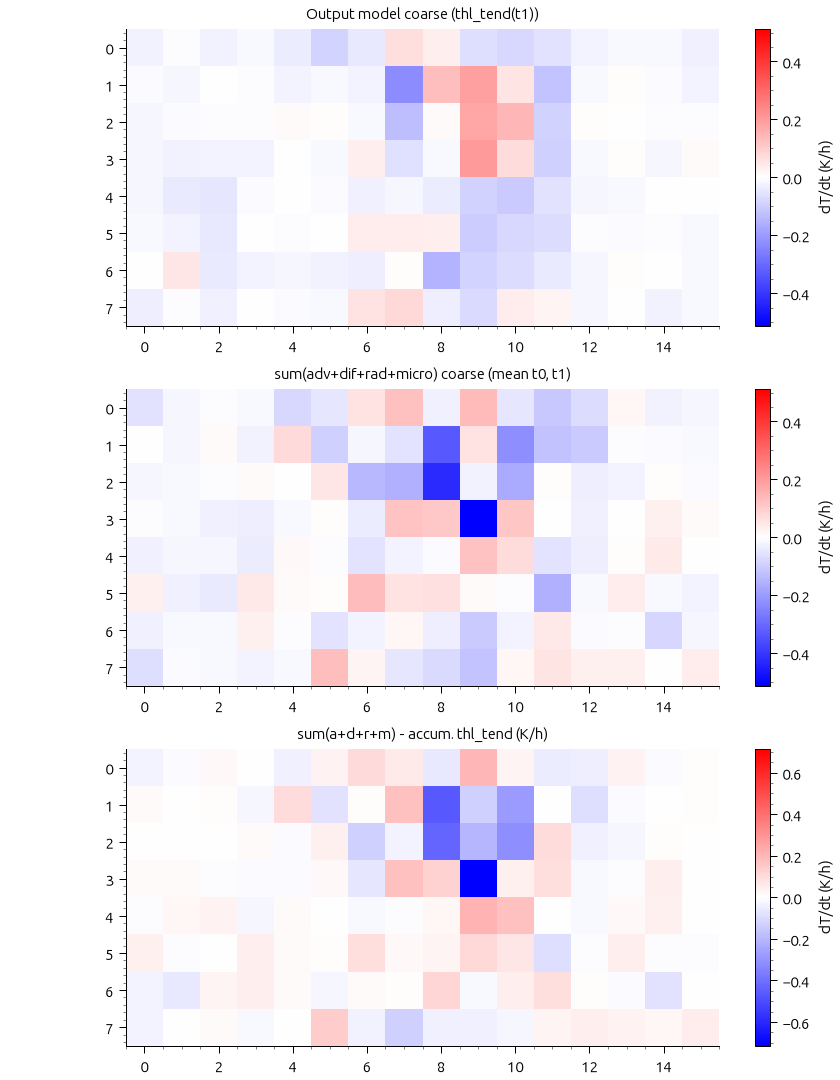

In [9]:
t0 = 169200
t1 = t0+3600

thlt_acc = load_c('thl_tend', t1)
thlt_diff = (load_c('thl', t1) - load_c('thl', t0)) / (t1 - t0)

def advdiff_inst(time):
    uthl_i = load_c('uthl', time)
    vthl_i = load_c('vthl', time)
    wthl_i = np.concatenate([load_c('wthl', time), np.zeros((1, jtot_c, itot_c))], axis=0)
    return (
        - (np.roll(uthl_i, -1, axis=2) - uthl_i) / dx_c
        - (np.roll(vthl_i, -1, axis=1) - vthl_i) / dy_c
        - (rhorefh[1:,None,None] * wthl_i[1:] - rhorefh[:-1,None,None] * wthl_i[:-1]) / (rhoref[:,None,None] * dz[:,None,None]) )

def rad_inst(time):
    return load_c('thl_tend_lw', time) + load_c('thl_tend_sw', time)

advdiff_h = 0.5 * (advdiff_inst(t0) + advdiff_inst(t1))
rad_h = 0.5 * (rad_inst(t0) + rad_inst(t1))
micro_h = 0.5 * (load_c('thl_tend_micro', t0) + load_c('thl_tend_micro', t1))

recon_h = advdiff_h + rad_h + micro_h

print('max |FD - model| (K/h):', np.abs(thlt_diff - thlt_acc).max()*3600)

plt.figure(figsize=(9,6), layout='constrained')
plt.subplot(121)
plt.title('Mean tendency coarse hourly (K/h)')
plt.plot(hmean(thlt_acc)*3600, z/1000, '-', color='tab:red', label='accum. thl_tend')
plt.plot(hmean(advdiff_h)*3600, z/1000, '-', color='tab:blue', lw=1, label='adv+diff (from flux div, mean t0, t1)')
plt.plot(hmean(rad_h)*3600, z/1000, '--', color='tab:blue', lw=1, label='rad (lw+sw, mean t0, t1)')
plt.plot(hmean(micro_h)*3600, z/1000, '-.', color='tab:blue', lw=1, label='micro (mean t0, t1)')
plt.plot(hmean(recon_h)*3600, z/1000, '--', color='k', label='sum(adv+dif+rad+micro)')
plt.xlabel('dT/dt (K/h)')
plt.ylabel('z (km)')
plt.legend()

plt.subplot(122)
plt.title('sum(a+d+r+m) - accum. thl_tend (K/h)')
plt.plot(hmean(recon_h - thlt_acc)*3600, z/1000, '-', color='k')
plt.xlabel('dT/dt (K/h)')
plt.ylabel('z (km)')

vmax = max(np.abs(thlt_acc[k]).max(), np.abs(recon_h[k]).max()) * 3600
vmin = -vmax
vdiff = np.abs(recon_h[k] - thlt_acc[k]).max() * 3600

plt.figure(figsize=(7,9), layout='constrained')
plt.subplot(311)
plt.title('Output model coarse (thl_tend(t1))')
plt.imshow(thlt_acc[k]*3600, vmin=vmin, vmax=vmax, cmap=plt.cm.bwr)
plt.colorbar(label='dT/dt (K/h)')

plt.subplot(312)
plt.title('sum(adv+dif+rad+micro) coarse (mean t0, t1)')
plt.imshow(recon_h[k]*3600, vmin=vmin, vmax=vmax, cmap=plt.cm.bwr)
plt.colorbar(label='dT/dt (K/h)')

plt.subplot(313)
plt.title('sum(a+d+r+m) - accum. thl_tend (K/h)')
plt.imshow((recon_h[k] - thlt_acc[k])*3600, vmin=-vdiff, vmax=vdiff, cmap=plt.cm.bwr)
plt.colorbar(label='dT/dt (K/h)')

## Discussion points.

- Moisture does not close. Do we need to store micro tend? Or calculate that term offline as closure?
- We could to the same for `thl`; exlude e.g. micro tend and calculate as closure?
- The hourly accumulated `thl_tend(t1)` is equal to simply `thl(t1) - thl(t0)`; exlude `thl_tend` from output? Would be cheaper as we don't have to accumulate the tendency every RK3 step.

Extra 3D_c output right now, compared to proposal:
- total micro tend thl = +1
- sedimentation micro split from total in warm/cold = +1

If we exlude `thl_tend` and `qt_tend`, that would bring the balance back to +0.

There is some budget output that I did not test, e.g. the sedimentation fluxes, freezing rate, etc.